# Классификация товаров по тексту

**Цель:** закодировать названия товаров и обучить классификатор.
Сначала два ответа — «обувь / остальные», затем восемь категорий.

Положите `kazanexpress_8000.csv` рядом с ноутбуком. Выполняйте ячейки сверху вниз.
Библиотеки: pandas, matplotlib, scikit-learn. При необходимости установите их командой `%pip install pandas matplotlib scikit-learn` в отдельной ячейке и перезапустите ядро.


## 1. Минимальное EDA

Одна строка — товар. **Признаки** получим из `title`, **правильный ответ** находится в `category`.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('kazanexpress_8000.csv')
df[['title', 'category']].head(3)


,title,category
0,"Сапоги женские с надставкой и утеплителем , -6...",Обувь
1,Домашняя одежда I принт Совы I пижама,Одежда
2,"Корм премиум класса для крыс и мышей, 1,5 кг",Зоотовары


### Категории и пропуски

`value_counts()` считает товары по категориям. `isna().sum()` считает пропуски.
Подвыборка специально сбалансирована; её доли не описывают весь маркетплейс.


In [2]:
print('Всего товаров:', len(df))
display(df['category'].value_counts())
df[['title', 'category']].isna().sum()


Всего товаров: 8000


category
Обувь              1000
Одежда             1000
Зоотовары          1000
Бытовая техника    1000
Канцтовары         1000
Электроника        1000
Спорт и отдых      1000
Красота            1000
Name: count, dtype: int64

title       0
category    0
dtype: int64

## 2. Разбиение данных

**Train — 60%:** обучаем словарь и модель. **Validation — 20%:** выбираем порог. **Test — 20%:** проверяем готовое решение.

`stratify` сохраняет доли категорий; `random_state` фиксирует случайное разбиение.
Сначала отделяем train, затем оставшиеся 40% делим пополам.


In [3]:
from sklearn.model_selection import train_test_split

train, rest = train_test_split(
    df, test_size=0.4, stratify=df['category'], random_state=42)
valid, test = train_test_split(
    rest, test_size=0.5, stratify=rest['category'], random_state=42)
print('Train:', len(train), 'Validation:', len(valid), 'Test:', len(test))


Train: 4800 Validation: 1600 Test: 1600


## 3. Кодирование текста
### Три названия из train

Для разбора берём короткие названия со словом «женские». `.between(12, 28)` выбирает длину текста, `.str.contains()` ищет слово, `.head(3)` оставляет три строки.


In [4]:
short_titles = train.loc[train['title'].str.len().between(12, 28), 'title']
examples = short_titles.loc[short_titles.str.contains('женские', case=False)].head(3)
examples


4477     Кеды женские, весна-осень
2233    Носочки женские укороченые
5223          Кеды женские, CROSBY
Name: title, dtype: object

### Мешок слов

Строка — товар, столбец — слово, число — сколько раз слово встретилось.
`fit_transform()` создаёт словарь и кодирует тексты. `.toarray()` используем только для маленького примера.


In [5]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

counter = CountVectorizer()
counts = counter.fit_transform(examples)
words = counter.get_feature_names_out()
pd.DataFrame(counts.toarray(), columns=words, index=examples)


,crosby,весна,женские,кеды,носочки,осень,укороченые
title,,,,,,,
"Кеды женские, весна-осень",0,1,1,1,0,1,0
Носочки женские укороченые,0,0,1,0,1,0,1
"Кеды женские, CROSBY",1,0,1,1,0,0,0


### TF-IDF

TF учитывает повторения слова в тексте, IDF — его распространённость среди текстов.
Редкие слова получают больший IDF. Общее слово «женские» получает меньший IDF, чем слова из одной карточки. Затем длина каждого непустого вектора нормируется.

Сравните числа с предыдущей таблицей. Порядок слов в таком представлении теряется.


In [6]:
tfidf = TfidfVectorizer()
weights = tfidf.fit_transform(examples)
pd.DataFrame(weights.toarray(), columns=tfidf.get_feature_names_out(), index=examples).round(2)


,crosby,весна,женские,кеды,носочки,осень,укороченые
title,,,,,,,
"Кеды женские, весна-осень",0.00,0.58,0.35,0.44,0.00,0.58,0.00
Носочки женские укороченые,0.00,0.00,0.39,0.00,0.65,0.00,0.65
"Кеды женские, CROSBY",0.72,0.00,0.43,0.55,0.00,0.00,0.00


## 4. Бинарная классификация
### Правильные ответы: 1 — обувь, 0 — остальные

`.eq('Обувь')` проверяет категорию. `.astype(int)` превращает True в 1, False в 0.


In [7]:
y_train = train['category'].eq('Обувь').astype(int)
y_valid = valid['category'].eq('Обувь').astype(int)
y_test = test['category'].eq('Обувь').astype(int)
print('Accuracy ответа «всё не обувь»:', 1 - y_valid.mean())


Accuracy ответа «всё не обувь»: 0.875


### Пайплайн: TF-IDF → логистическая регрессия

Пайплайн соединяет два шага. При `fit` словарь, IDF и коэффициенты модели обучаются **только по train**.
При прогнозе новые названия кодируются готовым векторизатором; незнакомые слова игнорируются.

`min_df=2` оставляет слова хотя бы из двух обучающих карточек. `max_iter` — предел итераций обучения.


In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

binary_model = make_pipeline(
    TfidfVectorizer(min_df=2, max_features=20_000),
    LogisticRegression(max_iter=500))
binary_model.fit(train['title'], y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('tfidfvectorizer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None


### Вероятность и ответ на validation

`predict_proba()` возвращает вероятности в порядке `classes_`. Здесь классы `[0, 1]`, столбец 1 относится к обуви.
Правило `p >= 0.5` превращает вероятность в ответ. Вероятность модели не является гарантией правильности.


In [9]:
print('Порядок классов:', binary_model.classes_)
p_valid = binary_model.predict_proba(valid['title'])[:, 1]
prediction = (p_valid >= 0.5).astype(int)
preview = valid[['title', 'category']].head(5).copy()
preview['P(обувь)'] = p_valid[:5]
preview['Прогноз 0/1'] = prediction[:5]
preview


Порядок классов: [0 1]


,title,category,P(обувь),Прогноз 0/1
567,"Тетрадь в клетку 48 листов, музыкальная тематика",Канцтовары,0.022805,0
7595,"Видеонаблюдение. Комплект: 9 камер 2Mp ""Дом""",Электроника,0.039903,0
4544,Грунт для аквариума,Зоотовары,0.033647,0
5496,"Кроссовки мужские, кеды спортивные",Обувь,0.983845,1
347,"Сет ""Шорты-топ""",Одежда,0.024949,0


## 5. Метрики бинарной классификации
### Матрица ошибок

Положительный класс — **обувь**. Строки показывают истину, столбцы — прогноз.

| | Прогноз: остальные | Прогноз: обувь |
|---|---|---|
| Истина: остальные | TN — верно отклонили | FP — ложное срабатывание |
| Истина: обувь | FN — пропустили | TP — верно нашли |


In [10]:
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

cm = confusion_matrix(y_valid, prediction, labels=[0, 1])
pd.DataFrame(cm, index=['Истина: остальные', 'Истина: обувь'],
             columns=['Прогноз: остальные', 'Прогноз: обувь'])


,Прогноз: остальные,Прогноз: обувь
Истина: остальные,1398,2
Истина: обувь,33,167


### Считаем метрики из четырёх чисел

- **Accuracy:** доля всех правильных ответов.
- **Precision:** какая доля найденной «обуви» действительно обувь.
- **Recall = TPR:** какую долю настоящей обуви нашли.
- **FPR:** какую долю остальных товаров ошибочно назвали обувью.
- **F1:** совместная оценка precision и recall.

`ravel()` читает матрицу по строкам: TN, FP, FN, TP. Обратите внимание на разные знаменатели TPR и FPR.


In [11]:
tn, fp, fn, tp = cm.ravel()
pd.Series({
    'Accuracy': (tp + tn) / cm.sum(),
    'Precision': tp / (tp + fp),
    'Recall = TPR': tp / (tp + fn),
    'FPR': fp / (fp + tn),
    'F1': 2 * tp / (2 * tp + fp + fn)
}).round(3)


Accuracy        0.978
Precision       0.988
Recall = TPR    0.835
FPR             0.001
F1              0.905
dtype: float64

### Меняем порог

Модель остаётся прежней. В коротком цикле проверяем три правила принятия решения.
Как изменятся FP и FN при снижении порога?


In [12]:
rows = []
for threshold in [0.2, 0.5, 0.8]:
    answer = (p_valid >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_valid, answer, labels=[0, 1]).ravel()
    rows.append([threshold, tp, fp, fn, tn,
                 tp / (tp + fn), fp / (fp + tn), 2 * tp / (2 * tp + fp + fn)])
thresholds = pd.DataFrame(rows, columns=['Порог', 'TP', 'FP', 'FN', 'TN', 'TPR', 'FPR', 'F1'])
thresholds.round(3)


,Порог,TP,FP,FN,TN,TPR,FPR,F1
0,0.2,194,14,6,1386,0.970,0.010,0.951
1,0.5,167,2,33,1398,0.835,0.001,0.905
2,0.8,88,0,112,1400,0.440,0.000,0.611


### ROC-кривая и ROC-AUC

Каждый порог задаёт точку **(FPR, TPR)**. Для ROC-AUC используем вероятности, а не ответы 0/1.
ROC-AUC оценивает разделение классов по оценкам модели: 0,5 — уровень случайного ранжирования, 1 — полное разделение на этой выборке.

Оранжевые точки — три проверенных порога. Высокий AUC не заменяет выбор порога и оценку precision/F1.


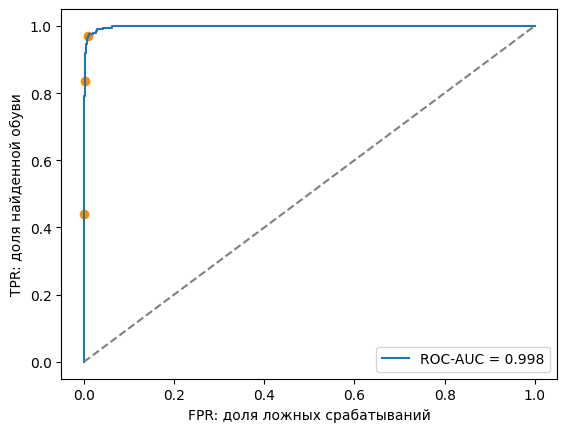

In [13]:
fpr, tpr, _ = roc_curve(y_valid, p_valid)
auc = roc_auc_score(y_valid, p_valid)
plt.plot(fpr, tpr, label=f'ROC-AUC = {auc:.3f}')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.scatter(thresholds['FPR'], thresholds['TPR'], color='darkorange')
plt.xlabel('FPR: доля ложных срабатываний')
plt.ylabel('TPR: доля найденной обуви')
plt.legend()


### Проверка на test

Выбираем лучший F1 **среди трёх порогов на validation**. `idxmax()` находит строку с максимумом; `.loc` читает её порог.
Затем применяем готовую модель и этот порог к test. После просмотра test порог не меняем.


In [14]:
best_row = thresholds['F1'].idxmax()
chosen_threshold = thresholds.loc[best_row, 'Порог']
p_test = binary_model.predict_proba(test['title'])[:, 1]
test_prediction = (p_test >= chosen_threshold).astype(int)
print('Выбранный порог:', chosen_threshold)


Выбранный порог: 0.2


### Тестовые метрики

Функции sklearn рассчитывают уже знакомые метрики. FPR снова считаем по настоящим отрицательным объектам.


In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

tn, fp, fn, tp = confusion_matrix(y_test, test_prediction, labels=[0, 1]).ravel()
pd.Series({
    'Accuracy': accuracy_score(y_test, test_prediction),
    'Precision': precision_score(y_test, test_prediction, zero_division=0),
    'Recall = TPR': recall_score(y_test, test_prediction),
    'FPR': fp / (fp + tn), 'F1': f1_score(y_test, test_prediction),
    'ROC-AUC': roc_auc_score(y_test, p_test)
}).round(3)


Accuracy        0.988
Precision       0.950
Recall = TPR    0.955
FPR             0.007
F1              0.953
ROC-AUC         0.993
dtype: float64

## 6. Многоклассовая классификация
### Тот же пайплайн, восемь ответов

`clone()` создаёт **необученную копию** пайплайна с теми же параметрами. Теперь в `fit` передаём названия восьми категорий.
Оставляем прежние признаки и разбиение; новых вариантов по test не подбираем.


In [16]:
from sklearn.base import clone

multi_model = clone(binary_model)
multi_model.fit(train['title'], train['category'])


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('tfidfvectorizer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None


### Восемь вероятностей вместо двух

Для одной карточки из validation покажем все вероятности. Они суммируются в 1; ответ — класс с наибольшей вероятностью.
Порядок классов берём из `classes_`.


In [17]:
example = valid['title'].head(1)
probabilities = multi_model.predict_proba(example)[0]
print(example.iloc[0])
print('Прогноз:', multi_model.predict(example)[0])
pd.Series(probabilities, index=multi_model.classes_, name='Вероятность').round(3)


Тетрадь в клетку 48 листов, музыкальная тематика
Прогноз: Канцтовары


Бытовая техника    0.007
Зоотовары          0.006
Канцтовары         0.943
Красота            0.006
Обувь              0.006
Одежда             0.016
Спорт и отдых      0.008
Электроника        0.008
Name: Вероятность, dtype: float64

### Метрики на test: по классам и macro

Для каждого класса считаем «эта категория против остальных».
**Macro** — простое среднее метрик по восьми классам с одинаковыми весами. Macro-F1 — среднее F1 по классам.
`support` — число настоящих объектов категории. В итоговой таблице добавим ROC-AUC.


In [18]:
from sklearn.metrics import classification_report

y_test_multi = test['category']
multi_prediction = multi_model.predict(test['title'])
multi_probabilities = multi_model.predict_proba(test['title'])
report = classification_report(y_test_multi, multi_prediction, output_dict=True, zero_division=0)
table = pd.DataFrame(report).T
table = table.loc[list(multi_model.classes_) + ['macro avg']]


### Многоклассовый ROC-AUC

**OvR (One-vs-Rest):** по очереди сравниваем каждую категорию с остальными, используя её вероятность. `average=None` возвращает восемь AUC; их среднее — macro ROC-AUC.
Это способ оценки. Он не означает, что логрег обучалась как восемь независимых бинарных моделей.


In [19]:
class_auc = roc_auc_score(
    y_test_multi, multi_probabilities, labels=multi_model.classes_,
    multi_class='ovr', average=None)
table['ROC-AUC'] = pd.Series(class_auc, index=multi_model.classes_)
table.loc['macro avg', 'ROC-AUC'] = class_auc.mean()
print('Test accuracy:', round(accuracy_score(y_test_multi, multi_prediction), 3))
table.round(3)


Test accuracy: 0.915


,precision,recall,f1-score,support,ROC-AUC
Бытовая техника,0.927,0.950,0.938,200.0,0.994
Зоотовары,0.955,0.855,0.902,200.0,0.986
Канцтовары,0.883,0.940,0.910,200.0,0.995
Красота,0.878,0.900,0.889,200.0,0.990
Обувь,0.985,0.970,0.977,200.0,0.994
Одежда,0.964,0.950,0.957,200.0,0.996
Спорт и отдых,0.797,0.845,0.820,200.0,0.980
Электроника,0.948,0.910,0.929,200.0,0.994
macro avg,0.917,0.915,0.915,1600.0,0.991


### Какие категории перепутаны

Диагональ — правильные ответы, остальные клетки — ошибки. Найдите самую частую пару перепутанных категорий.


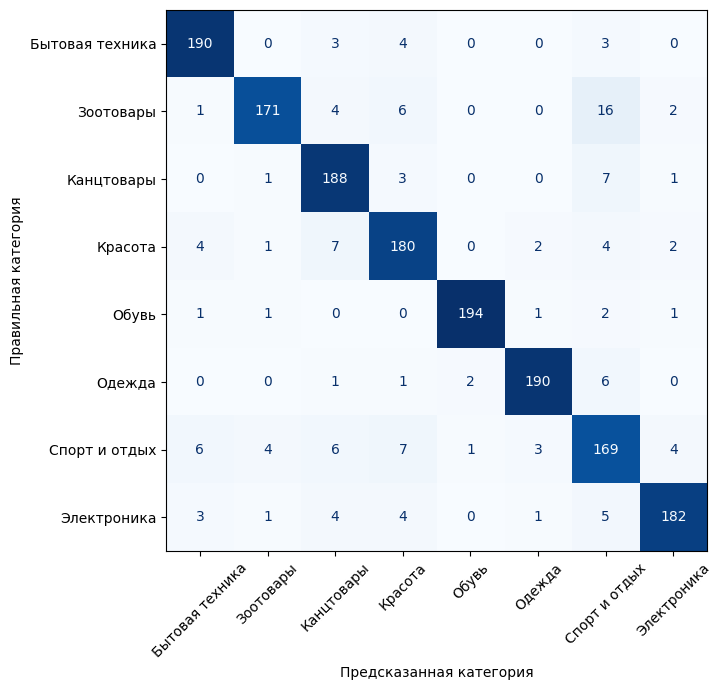

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay

chart = ConfusionMatrixDisplay.from_predictions(
    y_test_multi, multi_prediction, xticks_rotation=45, cmap='Blues', colorbar=False)
chart.ax_.set(xlabel='Предсказанная категория', ylabel='Правильная категория')
plt.gcf().set_size_inches(9, 7)
plt.tight_layout()


### Проверьте понимание

1. Почему ответ «всё не обувь» даёт 87,5% accuracy, но не решает задачу?
2. Чем отличаются знаменатели TPR и FPR?
3. У какой категории самый низкий recall? Что это означает для её товаров?

Источники: [исходные данные](https://huggingface.co/datasets/nyuuzyou/ke-products), [TF-IDF](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction), [метрики](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics).
